# Load data

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

t = pd.read_csv(r"C:/Users/49dhe/Desktop/project 2/1_DATA/telco_churn.csv")
print(t.shape)
print("Blank TotalCharges:", (t["TotalCharges"].str.strip() == "").sum())

(7043, 21)
Blank TotalCharges: 11


# Blank TotalCharges belong to brand-new customers (tenure 0), so they've paid nothing yet.

In [2]:
t["TotalCharges"] = pd.to_numeric(t["TotalCharges"], errors="coerce").fillna(0)
t["ChurnFlag"] = (t["Churn"] == "Yes").astype(int)
print("Churn rate:", round(t["ChurnFlag"].mean() * 100, 1), "%")

Churn rate: 26.5 %


# Groupping tenure

In [3]:
t["TenureGroup"] = pd.cut(t["tenure"], bins=[0, 12, 24, 48, 72],
                          labels=["0-12", "13-24", "25-48", "49-72"],
                          include_lowest=True)
t.groupby("TenureGroup", observed=True)["ChurnFlag"].agg(["mean", "size"]).round(3)

,mean,size
TenureGroup,,
0-12,0.474,2186
13-24,0.287,1024
25-48,0.204,1594
49-72,0.095,2239


# churn rate by each driver

In [4]:
drivers = ["Contract", "TenureGroup", "InternetService",
           "PaymentMethod", "TechSupport", "SeniorCitizen"]
for col in drivers:
    print(t.groupby(col, observed=True)["ChurnFlag"].mean().mul(100).round(1)
          .sort_values(ascending=False), "\n")

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8
Name: ChurnFlag, dtype: float64 

TenureGroup
0-12     47.4
13-24    28.7
25-48    20.4
49-72     9.5
Name: ChurnFlag, dtype: float64 

InternetService
Fiber optic    41.9
DSL            19.0
No              7.4
Name: ChurnFlag, dtype: float64 

PaymentMethod
Electronic check             45.3
Mailed check                 19.1
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Name: ChurnFlag, dtype: float64 

TechSupport
No                     41.6
Yes                    15.2
No internet service     7.4
Name: ChurnFlag, dtype: float64 

SeniorCitizen
1    41.7
0    23.6
Name: ChurnFlag, dtype: float64 



# one chart with all six drivers

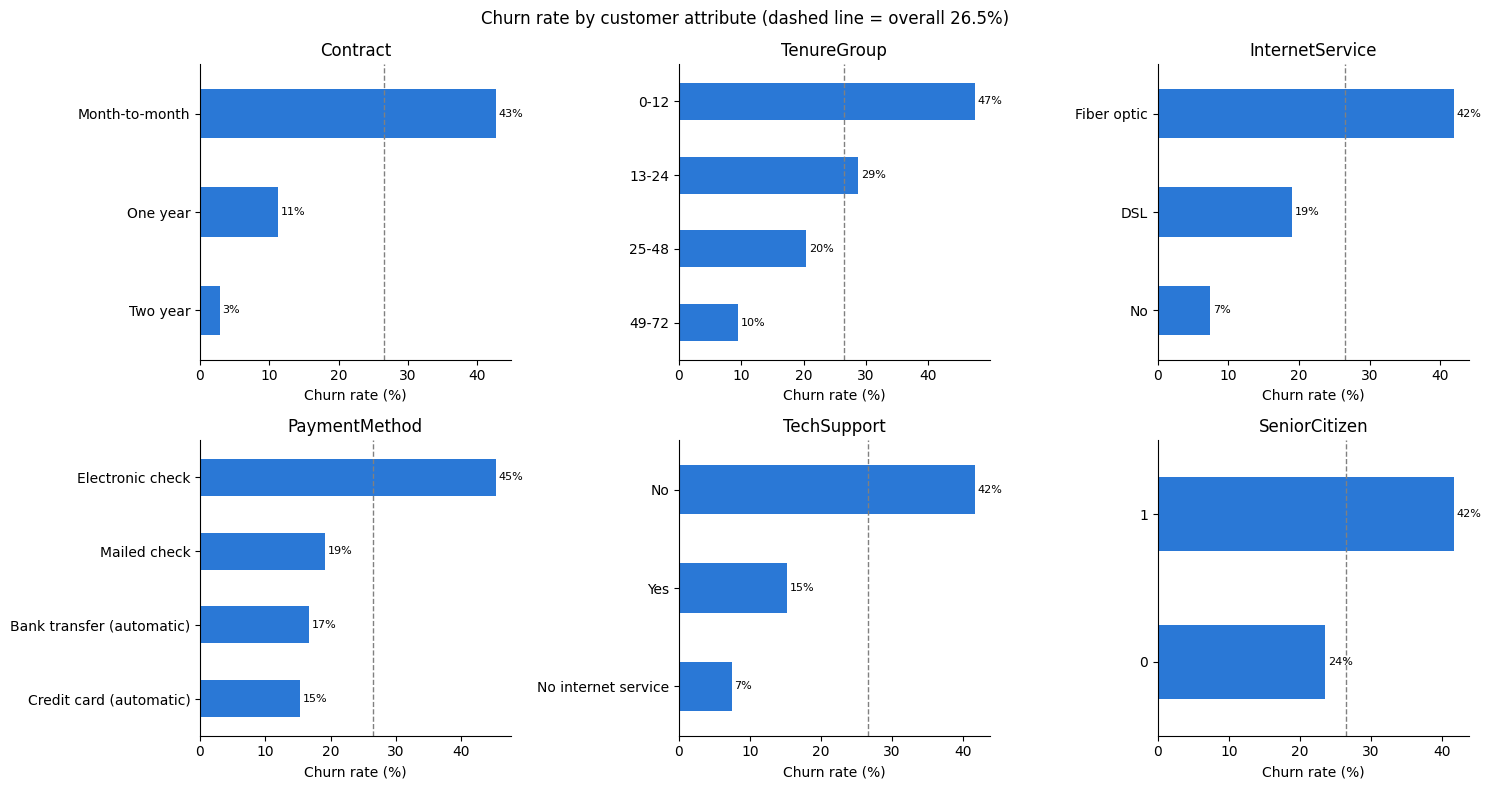

In [5]:
overall = t["ChurnFlag"].mean() * 100
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

for ax, col in zip(axes.flat, drivers):
    rate = t.groupby(col, observed=True)["ChurnFlag"].mean().mul(100).sort_values()
    rate.plot.barh(ax=ax, color="#2a78d6")
    ax.axvline(overall, color="grey", linestyle="--", linewidth=1)
    ax.set_title(col)
    ax.set_xlabel("Churn rate (%)")
    ax.set_ylabel("")
    for c in ax.containers:
        ax.bar_label(c, fmt="%.0f%%", fontsize=8, padding=2)

fig.suptitle(f"Churn rate by customer attribute (dashed line = overall {overall:.1f}%)")
sns.despine()
plt.tight_layout()
plt.savefig(r"C:/Users/49dhe/Desktop/project 2/5_IMAGE/churn_drivers.png", dpi=120)
plt.show()

# Revenue at

In [6]:
lost = t.loc[t["ChurnFlag"] == 1, "MonthlyCharges"].sum()
print("Monthly revenue from churned customers: $", round(lost, 2))
print("Share of monthly revenue:", round(lost / t["MonthlyCharges"].sum() * 100, 1), "%")
print(t.groupby("Churn")["MonthlyCharges"].mean().round(2))

Monthly revenue from churned customers: $ 139130.85
Share of monthly revenue: 30.5 %
Churn
No     61.27
Yes    74.44
Name: MonthlyCharges, dtype: float64


In [7]:
   t["LostRevenue"] = t["MonthlyCharges"] * t["ChurnFlag"]
   t.to_csv(r"C:/Users/49dhe/Desktop/project 2/1_DATA/telco_clean.csv", index=False)